In [ ]:
#数据基本信息（缺失值、数据类型、描述性统计）异常值检测（基于 IQR 或 Z-score）分布检查（直方图、箱线图）相关性分析（Pearson 相关系数）
#------------------------------------------------------------物理合理性检查（格陵兰岛的雪覆盖率和雪深度是否符合预期）
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 读取数据文件
data_path = r"F:\TUB\greenlandProject\ERA5LAND\merged_allfeature.csv"
df = pd.read_csv(data_path)

# 选择 snowc（雪覆盖率）和 sde（雪深度）列
snowc = df["snowc"]  # 单位：%
sde = df["sde"]  # 单位：米

# 基本统计信息
print("基本统计信息：")
print(df[["snowc", "sde"]].describe())

# 检查缺失值
df_missing = df[["snowc", "sde"]].isnull().sum()
print("\n缺失值情况：")
print(df_missing)

# 直方图查看分布
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(snowc, bins=50, kde=True)
plt.title("Snow Cover Distribution")
plt.xlabel("Snow Cover (%)")

plt.subplot(1, 2, 2)
sns.histplot(sde, bins=50, kde=True)
plt.title("Snow Depth Distribution")
plt.xlabel("Snow Depth (m)")
plt.show()

# 箱线图检测异常值
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.boxplot(x=snowc)
plt.title("Snow Cover Boxplot")

plt.subplot(1, 2, 2)
sns.boxplot(x=sde)
plt.title("Snow Depth Boxplot")
plt.show()

# 计算皮尔逊相关系数
correlation = snowc.corr(sde)
print("\n雪覆盖率与雪深度的相关性：", correlation)

# IQR 方法检测异常值
Q1_snowc, Q3_snowc = np.percentile(snowc.dropna(), [25, 75])
IQR_snowc = Q3_snowc - Q1_snowc
lower_bound_snowc = Q1_snowc - 1.5 * IQR_snowc
upper_bound_snowc = Q3_snowc + 1.5 * IQR_snowc

Q1_sde, Q3_sde = np.percentile(sde.dropna(), [25, 75])
IQR_sde = Q3_sde - Q1_sde
lower_bound_sde = Q1_sde - 1.5 * IQR_sde
upper_bound_sde = Q3_sde + 1.5 * IQR_sde

outliers_snowc = ((snowc < lower_bound_snowc) | (snowc > upper_bound_snowc)).sum()
outliers_sde = ((sde < lower_bound_sde) | (sde > upper_bound_sde)).sum()

print(f"\n雪覆盖率的异常值数量: {outliers_snowc}")
print(f"雪深度的异常值数量: {outliers_sde}")


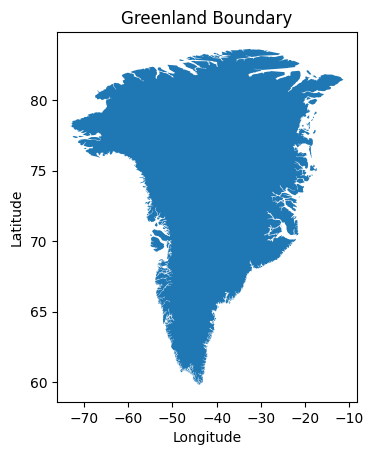

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt

# 加载 shapefile
shapefile_path = r'F:\TUB\greenlandProject\ne_10m_admin_0_countries\greenland_boundary.shp'
gdf = gpd.read_file(shapefile_path)

# 绘制地图
gdf.plot()
plt.title('Greenland Boundary')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()




In [ ]:
# ---Step 6: SHAP格式检查---SHAP-----------SHAP-----------------SHAP--------------------------SHAP-------------------------------SHAP
print("Quick SHAP check with small model...")
try:
    small_rf = RandomForestRegressor(n_estimators=10, max_depth=5, random_state=42)
    small_rf.fit(X_scaled, y)
    explainer = shap.TreeExplainer(small_rf)
    shap_values_check = explainer.shap_values(X_scaled[:100])  # 只检查前100个样本
    print(f"Quick SHAP check passed. SHAP shape: {shap_values_check[0].shape}, X shape: {X_scaled.shape}")
except Exception as e:
    print(f"Error during quick SHAP check: {e}")
    raise ValueError("SHAP check failed, stop training!")



# ---Step 10: SHAP分析堆叠模型---
print("\nPlotting SHAP summary for original features in the ensemble model...")

def ensemble_predict(X_input):
    X_input_scaled = scaler.transform(X_input)
    preds = np.zeros((X_input.shape[0], len(models)))
    for i, (name, model) in enumerate(models.items()):
        preds[:, i] = model.predict(X_input_scaled)
    return meta_model.predict(preds)

try:
    background = shap.sample(X.values, 100)
    explainer = shap.KernelExplainer(ensemble_predict, background)

    sample_indices = np.random.choice(len(X), size=min(100, len(X)), replace=False)
    X_sample = X.values[sample_indices]
    shap_values = explainer.shap_values(X_sample)
    
    FEATURE_NAMES = [name.upper() for name in input_features]
    
    plt.figure(figsize=(12, 6))
    shap.summary_plot(shap_values, X_sample, feature_names=FEATURE_NAMES, plot_type="bar", show=False)
    plt.title("ENSEMBLE MODEL FEATURE IMPORTANCE (BAR PLOT)", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    plt.figure(figsize=(12, 8))
    shap.summary_plot(shap_values, X_sample, feature_names=FEATURE_NAMES, show=False)
    plt.title("ENSEMBLE MODEL SHAP VALUES", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

    print("SHAP analysis for original features completed.")
except Exception as e:
    print(f"Error during SHAP analysis: {e}")

Loading data...
Data loaded with columns: ['longitude', 'latitude', 'altitude_last_valid', 'sp', 'ssrd', 'str', 'strd', 't2m', 'u10', 'v10', 'snowc', 'sde', 'asn', 'year', 'month', 'albedo', 'station']
Starting cross-validation for base models...
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000625 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2294
[LightGBM] [Info] Number of data points in the train set: 3132, number of used features: 15
[LightGBM] [Info] Start training from score 0.722090
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000274 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2283
[LightGBM] [Info] Number of data points in the train set: 3133, number of used features: 15
[LightGBM] [Info] Start training from score 0.720260


E:\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
E:\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
E:\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000398 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2289
[LightGBM] [Info] Number of data points in the train set: 3133, number of used features: 15
[LightGBM] [Info] Start training from score 0.721139
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000327 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2280
[LightGBM] [Info] Number of data points in the train set: 3133, number of used features: 15
[LightGBM] [Info] Start training from score 0.721412
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000283 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2288
[LightGBM] [Info] Number of data points in the train set: 3133, number of used features: 15
[LightGBM] [Info] Start traini

E:\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
E:\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


RF: RMSE=0.078590, R=0.904658
XGB: RMSE=0.079607, R=0.902427
GBDT: RMSE=0.084334, R=0.889689
LGBM: RMSE=0.075551, R=0.912392
SVR: RMSE=0.085952, R=0.885038

Training stacking meta model...
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000528 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2294
[LightGBM] [Info] Number of data points in the train set: 3132, number of used features: 15
[LightGBM] [Info] Start training from score 0.722090


...

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000543 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2288
[LightGBM] [Info] Number of data points in the train set: 3133, number of used features: 15
[LightGBM] [Info] Start training from score 0.720430


E:\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(



Meta Model Performance (Cross-Validated):
RMSE=0.075169, R=0.913432

Loading train and test set for final evaluation...
Train and Test data loaded successfully.

Retraining base models on full training set...
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000349 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2307
[LightGBM] [Info] Number of data points in the train set: 3916, number of used features: 15
[LightGBM] [Info] Start training from score 0.721066


E:\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(



Retraining meta model...

Saving final models and scaler...
Models and scaler saved successfully.

Evaluating final model on test set...
Test Set Evaluation:
Correlation (Pearson's r): 0.917725
RMSE: 0.076198
MAE: 0.051201
Bias: 0.000000

预测结果已保存到文件: F:/TUB/greenlandProject/ERA5LAND/test_with_predictions.csv

Generating visualizations...


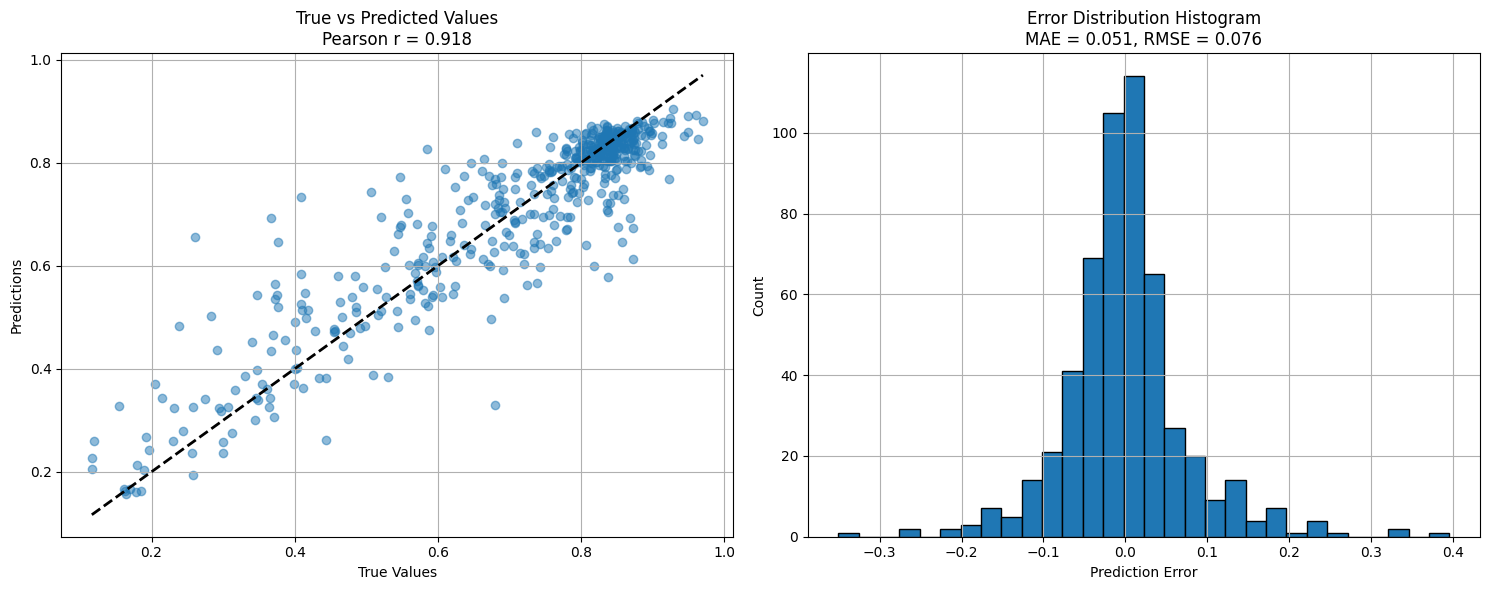

Visualizations saved as 'model_performance_visualization.png'


In [1]:
# -----------------------划分训练/验证集-----------------------基础模型-----------------堆叠模型-----------------------验证集偏差计算---------------------------
import pandas as pd
import shap
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from xgboost import XGBRegressor
import lightgbm as lgb
import numpy as np
from sklearn.base import clone
import pickle
from scipy.stats import pearsonr

# ---Step 1: 数据加载---
file_path = "F:/TUB/greenlandProject/ERA5LAND/train.csv"
print("Loading data...")

try:
    df = pd.read_csv(file_path, delimiter=',')
    df.columns = df.columns.str.strip()  # 去除列名中的空格
    print(f"Data loaded with columns: {df.columns.tolist()}")  # 打印列名确认
except Exception as e:
    print(f"Error loading data: {e}")
    raise e

# ---Step 4: 特征选择与准备---
input_features = ['longitude', 'latitude', 'altitude_last_valid', 'sp', 'ssrd', 'str', 'strd', 
               't2m', 'u10', 'v10', 'snowc', 'sde', 'asn', 'year', 'month']

output_feature = 'albedo'

# 直接用df而不是df_filtered
X = df[input_features]
y = df[output_feature]

# ---Step 5: 数据标准化---
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ---Step 7: 基学习器训练（交叉验证）---
models = {
    'RF': RandomForestRegressor(n_jobs=-1, random_state=42),
    'XGB': XGBRegressor(n_jobs=-1, random_state=42),
    'GBDT': GradientBoostingRegressor(random_state=42),
    'LGBM': lgb.LGBMRegressor(n_jobs=-1, random_state=42),
    'SVR': SVR(kernel='rbf')
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)

base_model_performance = {}
print("Starting cross-validation for base models...")

for model_name, model in models.items():
    rmse_list = []
    r_list = []  # Changed from r2_list to r_list for Pearson's r
    for train_idx, val_idx in kf.split(X_scaled):
        X_train, X_val = X_scaled[train_idx], X_scaled[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

        model.fit(X_train, y_train)
        y_pred = model.predict(X_val)

        rmse = np.sqrt(mean_squared_error(y_val, y_pred))
        r, _ = pearsonr(y_val, y_pred)  # Calculate Pearson's r instead of R²

        rmse_list.append(rmse)
        r_list.append(r)

    base_model_performance[model_name] = {
        'RMSE_mean': np.mean(rmse_list),
        'R_mean': np.mean(r_list)  # Changed from R2_mean to R_mean
    }

for model_name, performance in base_model_performance.items():
    print(f"{model_name}: RMSE={performance['RMSE_mean']:.6f}, R={performance['R_mean']:.6f}")

# ---Step 8: 堆叠元模型训练---
print("\nTraining stacking meta model...")
base_preds = np.zeros((len(X_scaled), len(models)))

for train_idx, test_idx in kf.split(X_scaled):
    X_train, X_test = X_scaled[train_idx], X_scaled[test_idx]
    y_train = y.iloc[train_idx]
    
    for i, (name, model) in enumerate(models.items()):
        cloned_model = clone(model)
        cloned_model.fit(X_train, y_train)
        base_preds[test_idx, i] = cloned_model.predict(X_test)

meta_model = Ridge()
meta_model.fit(base_preds, y)

# ---Step 9: 元模型交叉验证评估---
meta_rmse_list = []
meta_r_list = []  # Changed from meta_r2_list to meta_r_list

for train_idx, test_idx in kf.split(base_preds):
    X_meta_train, X_meta_test = base_preds[train_idx], base_preds[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    
    cloned_meta = clone(meta_model)
    cloned_meta.fit(X_meta_train, y_train)
    y_pred = cloned_meta.predict(X_meta_test)
    
    meta_rmse_list.append(np.sqrt(mean_squared_error(y_test, y_pred)))
    r, _ = pearsonr(y_test, y_pred)  # Calculate Pearson's r
    meta_r_list.append(r)

print("\nMeta Model Performance (Cross-Validated):")
print(f"RMSE={np.mean(meta_rmse_list):.6f}, R={np.mean(meta_r_list):.6f}")

# ---Step 11: 加载最终train/test集---
print("\nLoading train and test set for final evaluation...")

train_path = "F:/TUB/greenlandProject/ERA5LAND/train.csv"
test_path = "F:/TUB/greenlandProject/ERA5LAND/test.csv"

try:
    train_df = pd.read_csv(train_path)
    test_df = pd.read_csv(test_path)
    train_df.columns = train_df.columns.str.strip()
    test_df.columns = test_df.columns.str.strip()
    print("Train and Test data loaded successfully.")
except Exception as e:
    print(f"Error loading train/test data: {e}")
    raise e

X_train_full = train_df[input_features]
y_train_full = train_df[output_feature]
X_test_final = test_df[input_features]
y_test_final = test_df[output_feature]

scaler_final = StandardScaler()
X_train_scaled = scaler_final.fit_transform(X_train_full)
X_test_scaled = scaler_final.transform(X_test_final)

# ---Step 12: 基学习器重新训练---
print("\nRetraining base models on full training set...")
final_models = {}
for name, model in models.items():
    cloned_model = clone(model)
    cloned_model.fit(X_train_scaled, y_train_full)
    final_models[name] = cloned_model

base_preds_test = np.zeros((len(X_test_final), len(final_models)))
for i, (name, model) in enumerate(final_models.items()):
    base_preds_test[:, i] = model.predict(X_test_scaled)

# ---Step 13: 元模型重新训练---
print("\nRetraining meta model...")
meta_model_final = Ridge()
meta_model_final.fit(base_preds_test, y_test_final)

# ---Step 14: 保存模型---
print("\nSaving final models and scaler...")
with open('final_models.pkl', 'wb') as f:
    pickle.dump(final_models, f)
with open('meta_model.pkl', 'wb') as f:
    pickle.dump(meta_model_final, f)
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler_final, f)
print("Models and scaler saved successfully.")

# ---Step 15: 测试集上性能评估---
print("\nEvaluating final model on test set...")
meta_preds = meta_model_final.predict(base_preds_test)

corr, _ = pearsonr(y_test_final, meta_preds)
rmse = np.sqrt(mean_squared_error(y_test_final, meta_preds))
mae = mean_absolute_error(y_test_final, meta_preds)
bias = np.mean(meta_preds - y_test_final)

print(f"Test Set Evaluation:")
print(f"R²: {r2:.6f}")
print(f"Correlation (Pearson's r): {corr:.6f}")
print(f"RMSE: {rmse:.6f}")
print(f"MAE: {mae:.6f}")
print(f"Bias: {bias:.6f}")



# ---新增步骤：输出测试集的真实值和预测值到"  F:\TUB\greenlandProject\ERA5LAND\test_with_predictions.csv"  ---
import pandas as pd

test_df = pd.read_csv("F:/TUB/greenlandProject/ERA5LAND/test.csv") 

if 'albedo' not in test_df.columns:
    test_df['albedo'] = y_test_final  # 添加真实值列（albedo）

# 添加预测值列
test_df['predicted_albedo'] = meta_preds  # 列名可自定义

# 计算绝对误差（可选）
test_df['absolute_error'] = np.abs(test_df['albedo'] - test_df['predicted_albedo'])

# 保存到新文件
output_path = "F:/TUB/greenlandProject/ERA5LAND/test_with_predictions.csv"
test_df.to_csv(output_path, index=False)
print(f"\n预测结果已保存到文件: {output_path}")




# ---Step 16: 可视化---
print("\nGenerating visualizations...")
plt.figure(figsize=(15, 6))

# 散点图：预测值 vs 真实值
plt.subplot(1, 2, 1)
plt.scatter(y_test_final, meta_preds, alpha=0.5)
plt.plot([y_test_final.min(), y_test_final.max()], 
         [y_test_final.min(), y_test_final.max()], 'k--', lw=2)
plt.xlabel('True Values')
plt.ylabel('Predictions')
plt.title(f'True vs Predicted Values\nPearson r = {corr:.3f}')
plt.grid(True)

# 误差分布直方图
plt.subplot(1, 2, 2)
errors = meta_preds - y_test_final
plt.hist(errors, bins=30, edgecolor='black')
plt.xlabel('Prediction Error')
plt.ylabel('Count')
plt.title('Error Distribution Histogram\nMAE = {:.3f}, RMSE = {:.3f}'.format(mae, rmse))
plt.grid(True)

plt.tight_layout()
plt.savefig('model_performance_visualization.png', dpi=300)
plt.show()
print("Visualizations saved as 'model_performance_visualization.png'")

In [16]:
import pandas as pd
import pickle
import numpy as np

# 1. 读取数据
csv_file_path = r'F:\TUB\greenlandProject\ERA5LAND\202008train_with_altitude.csv'
df = pd.read_csv(csv_file_path)

# 2. 查找包含缺失值的行
df_missing = df[df[input_columns].isnull().any(axis=1)]  # 包含缺失值的行
df_no_missing = df.dropna(subset=input_columns)  # 删除包含缺失值的行

# 3. 打印缺失值的行
print(f"包含缺失值的行数: {df_missing.shape[0]}")
print(df_missing)  # 打印包含缺失值的行

# 4. 加载模型和Scaler
with open('final_models.pkl', 'rb') as f:
    final_models = pickle.load(f)
with open('meta_model.pkl', 'rb') as f:
    meta_model_final = pickle.load(f)
with open('scaler.pkl', 'rb') as f:
    scaler_final = pickle.load(f)

# 3. 定义输入特征的顺序（确保与训练时一致）
input_columns = ['longitude', 'latitude', 'altitude_last_valid', 'sp', 'ssrd', 'str', 'strd', 
               't2m', 'u10', 'v10', 'snowc', 'sde', 'asn', 'year', 'month']



# 5. 对不包含缺失值的行进行标准化和预测
X_input_no_missing = df_no_missing[input_columns]  # 提取没有缺失值的输入数据
X_input_scaled = scaler_final.transform(X_input_no_missing)  # 对数据进行标准化

# 6. 使用各个基学习器进行预测
predictions = {}
for model_name, model in final_models.items():
    predictions[model_name] = model.predict(X_input_scaled)

# 7. 堆叠模型预测（组合基模型的预测结果）
base_preds = np.column_stack([predictions[model_name] for model_name in final_models.keys()])
final_albedo = meta_model_final.predict(base_preds)

# 8. 将预测结果添加到数据框
df_no_missing['albedo'] = final_albedo

# 9. 合并结果到原始数据框
df_combined = pd.concat([df_no_missing, df_missing])

# 10. 保存结果
output_file_path = r'F:\TUB\greenlandProject\ERA5LAND\202008train_with_albedo.csv'
df_combined.to_csv(output_file_path, index=False)

print("✅ 预测完成，albedo列已添加并保存！")




包含缺失值的行数: 4147
       latitude  longitude        sp      ssrd      str      strd        t2m  \
82482      57.9      -75.0  98471.75  14123638 -4934432  28624826  286.43774   
82483      57.9      -74.9  98290.75  14097662 -4900124  28635134  286.40063   
82484      57.9      -74.8  98143.75  14073064 -4868552  28643910  286.38110   
82485      57.9      -74.7  98132.75  14056818 -4850074  28650494  286.40454   
82486      57.9      -74.6  98174.75  14041852 -4837226  28656750  286.44946   
...         ...        ...       ...       ...      ...       ...        ...   
86624      55.0      -59.5  99594.75  14559638 -4408946  29408918  287.69556   
86625      55.0      -59.4  99005.75  14644712 -4261878  29370198  287.25806   
86626      55.0      -59.3  98622.75  14725536 -4171906  29346330  286.95337   
86627      55.0      -59.2  98455.75  14802166 -4088552  29337154  286.77954   
86628      55.0      -59.1  98574.75  14843484 -4084868  29334986  286.80298   

            u10       v1

E:\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
C:\Users\11823\AppData\Local\Temp\ipykernel_16960\698360730.py:45: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_no_missing['albedo'] = final_albedo


✅ 预测完成，albedo列已添加并保存！


In [ ]:
#--------------------------根据气象参数input---------推理计算2020 年所有月份----------------输出output---------albedo-----------
import pandas as pd
import pickle
import numpy as np
import os

# 定义输入特征的顺序（确保与训练时一致）
input_columns = ['longitude', 'latitude', 'altitude_last_valid', 'sp', 'ssrd', 'str', 'strd', 
               't2m', 'u10', 'v10', 'snowc', 'sde', 'asn', 'year', 'month']

# 加载模型和Scaler（只需加载一次）
with open('final_models.pkl', 'rb') as f:
    final_models = pickle.load(f)
with open('meta_model.pkl', 'rb') as f:
    meta_model_final = pickle.load(f)
with open('scaler.pkl', 'rb') as f:
    scaler_final = pickle.load(f)

# 定义处理单个文件的函数
def process_file(file_path):
    # 1. 读取数据
    df = pd.read_csv(file_path)
    
    # 2. 查找包含缺失值的行
    df_missing = df[df[input_columns].isnull().any(axis=1)]  # 包含缺失值的行
    df_no_missing = df.dropna(subset=input_columns)  # 删除包含缺失值的行
    
    # 3. 打印缺失值的行
    print(f"处理文件: {os.path.basename(file_path)}")
    print(f"包含缺失值的行数: {df_missing.shape[0]}")
    
    # 如果没有有效数据，跳过预测
    if len(df_no_missing) == 0:
        print("⚠️ 警告: 没有有效数据可供预测，跳过此文件")
        return
    
    # 4. 对不包含缺失值的行进行标准化和预测
    X_input_no_missing = df_no_missing[input_columns]  # 提取没有缺失值的输入数据
    X_input_scaled = scaler_final.transform(X_input_no_missing)  # 对数据进行标准化
    
    # 5. 使用各个基学习器进行预测
    predictions = {}
    for model_name, model in final_models.items():
        predictions[model_name] = model.predict(X_input_scaled)
    
    # 6. 堆叠模型预测（组合基模型的预测结果）
    base_preds = np.column_stack([predictions[model_name] for model_name in final_models.keys()])
    final_albedo = meta_model_final.predict(base_preds)
    
    # 7. 将预测结果添加到数据框
    df_no_missing['albedo'] = final_albedo
    
    # 8. 合并结果到原始数据框
    df_combined = pd.concat([df_no_missing, df_missing])
    
    # 9. 保存结果
    output_file_path = file_path.replace('.csv', '_with_albedo.csv')
    df_combined.to_csv(output_file_path, index=False)
    print(f"✅ 预测完成，结果已保存到: {output_file_path}\n")

# 主处理流程
folder_path = r'F:\TUB\greenlandProject\ERA5LAND\2020'

# 遍历文件夹中的所有CSV文件
for file_name in os.listdir(folder_path):
    if file_name.endswith('.csv'):
        file_path = os.path.join(folder_path, file_name)
        process_file(file_path)

print("所有文件处理完成！")